In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 3\WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [5]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Rows: 0
Dataset Shape After Removing Duplicates: (7043, 21)


In [6]:
for column in df.select_dtypes(include="object").columns:
    print("\n", column)
    print(df[column].unique()[:10])


 customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' '7795-CFOCW' '9237-HQITU'
 '9305-CDSKC' '1452-KIOVK' '6713-OKOMC' '7892-POOKP' '6388-TABGU']

 gender
['Female' 'Male']

 Partner
['Yes' 'No']

 Dependents
['No' 'Yes']

 PhoneService
['No' 'Yes']

 MultipleLines
['No phone service' 'No' 'Yes']

 InternetService
['DSL' 'Fiber optic' 'No']

 OnlineSecurity
['No' 'Yes' 'No internet service']

 OnlineBackup
['Yes' 'No' 'No internet service']

 DeviceProtection
['No' 'Yes' 'No internet service']

 TechSupport
['No' 'Yes' 'No internet service']

 StreamingTV
['No' 'Yes' 'No internet service']

 StreamingMovies
['No' 'Yes' 'No internet service']

 Contract
['Month-to-month' 'One year' 'Two year']

 PaperlessBilling
['Yes' 'No']

 PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

 TotalCharges
['29.85' '1889.5' '108.15' '1840.75' '151.65' '820.5' '1949.4' '301.9'
 '3046.05' '3487.95']

 Churn
['No' 'Yes']


In [7]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

median_value = df["TotalCharges"].median()
df["TotalCharges"] = df["TotalCharges"].fillna(median_value)

print("TotalCharges converted and missing values handled!")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

TotalCharges converted and missing values handled!
Missing TotalCharges: 0


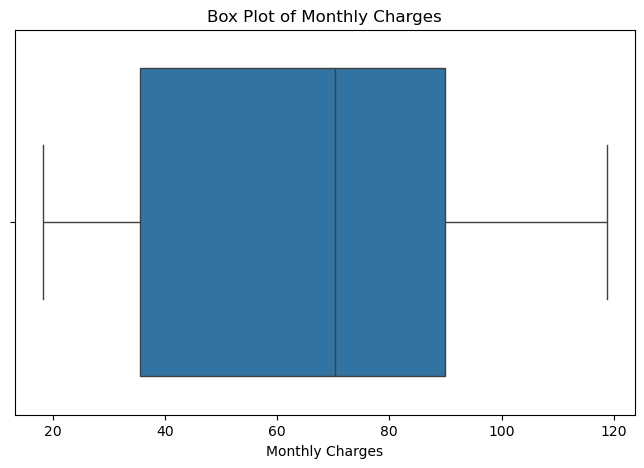

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["MonthlyCharges"])
plt.title("Box Plot of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.show()

In [9]:
Q1 = df["MonthlyCharges"].quantile(0.25)
Q3 = df["MonthlyCharges"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df = df[(df["MonthlyCharges"] >= lower_limit) & (df["MonthlyCharges"] <= upper_limit)]

print("Outliers removed successfully!")
print("Updated Dataset Shape:", df.shape)

Outliers removed successfully!
Updated Dataset Shape: (7043, 21)


In [10]:
df["AverageMonthlyCharges"] = df["MonthlyCharges"]

print("New Feature Created!")
df[["MonthlyCharges", "AverageMonthlyCharges"]].head()

New Feature Created!


,MonthlyCharges,AverageMonthlyCharges
0,29.85,29.85
1,56.95,56.95
2,53.85,53.85
3,42.30,42.30
4,70.70,70.70


In [11]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for column in df.select_dtypes(include="object").columns:
    df[column] = le.fit_transform(df[column].astype(str))

print("Categorical Encoding Completed!")
df.head()

Categorical Encoding Completed!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,AverageMonthlyCharges
0,5375,0,0,1,0,1,0,1,0,0,...,0,0,0,0,1,2,29.85,29.85,0,29.85
1,3962,1,0,0,0,34,1,0,0,2,...,0,0,0,1,0,3,56.95,1889.50,0,56.95
2,2564,1,0,0,0,2,1,0,0,2,...,0,0,0,0,1,3,53.85,108.15,1,53.85
3,5535,1,0,0,0,45,0,1,0,2,...,2,0,0,1,0,0,42.30,1840.75,0,42.30
4,6511,0,0,0,0,2,1,0,1,0,...,0,0,0,0,1,2,70.70,151.65,1,70.70


In [12]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nFinal Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

Missing Values:
0

Final Dataset Shape: (7043, 22)

Data Types:
customerID                 int64
gender                     int64
SeniorCitizen              int64
Partner                    int64
Dependents                 int64
tenure                     int64
PhoneService               int64
MultipleLines              int64
InternetService            int64
OnlineSecurity             int64
OnlineBackup               int64
DeviceProtection           int64
TechSupport                int64
StreamingTV                int64
StreamingMovies            int64
Contract                   int64
PaperlessBilling           int64
PaymentMethod              int64
MonthlyCharges           float64
TotalCharges             float64
Churn                      int64
AverageMonthlyCharges    float64
dtype: object


In [13]:
df.to_csv("cleaned_telecom_churn.csv", index=False)

print("Cleaned Telecom Churn Dataset Saved Successfully!")

Cleaned Telecom Churn Dataset Saved Successfully!


In [14]:
cleaned_df = pd.read_csv("cleaned_telecom_churn.csv")

print("Saved Dataset Shape:", cleaned_df.shape)
print("Dataset Loaded Successfully!")
cleaned_df.head()

Saved Dataset Shape: (7043, 22)
Dataset Loaded Successfully!


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,AverageMonthlyCharges
0,5375,0,0,1,0,1,0,1,0,0,...,0,0,0,0,1,2,29.85,29.85,0,29.85
1,3962,1,0,0,0,34,1,0,0,2,...,0,0,0,1,0,3,56.95,1889.50,0,56.95
2,2564,1,0,0,0,2,1,0,0,2,...,0,0,0,0,1,3,53.85,108.15,1,53.85
3,5535,1,0,0,0,45,0,1,0,2,...,2,0,0,1,0,0,42.30,1840.75,0,42.30
4,6511,0,0,0,0,2,1,0,1,0,...,0,0,0,0,1,2,70.70,151.65,1,70.70
